In [10]:
import pandas as pd 
import numpy as np
import scipy as sns
import scipy.stats as stats
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_predict

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer


In [4]:
df = pd.read_csv("titanic.csv", usecols=['Age', 'Fare', 'Survived'])
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


age wale column me kuchh mission value thi us fill karne ke liye eek function use kiye hai jise hm fillna method ka use karke age ka  mean value  missing valuve me put kar rahe hai 


In [5]:
df['Age'].fillna(df['Age'].mean(),inplace=True)

C:\Users\visha\AppData\Local\Temp\ipykernel_18420\694922604.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(),inplace=True)


In [6]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [7]:
x = df.iloc[:,1:3]
y = df.iloc[:,0]

In [9]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

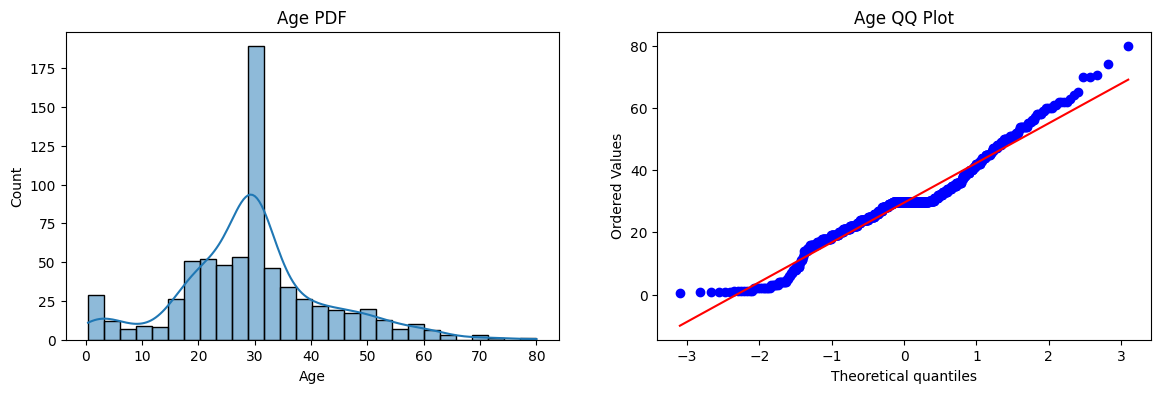

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(x_train['Age'], kde=True)
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['Age'], dist="norm", plot=plt)
plt.title("Age QQ Plot")

plt.show()

Text(0.5, 1.0, 'Age QQ Plot')

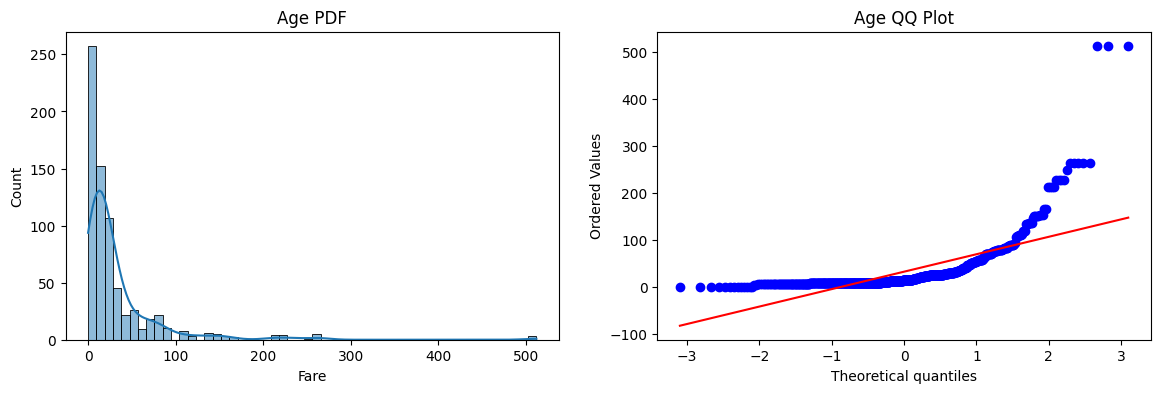

In [15]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(x_train['Fare'], kde=True)
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['Fare'], dist="norm", plot=plt)
plt.title("Age QQ Plot")


In [18]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [19]:
clf.fit(x_train, y_train)
clf2.fit(x_train, y_train)

y_pred = clf.predict(x_test)
y_pred1 = clf2.predict(x_test)

print("accuracy LR", accuracy_score(y_test,y_pred))
print("accuracy DT", accuracy_score(y_test,y_pred1))

accuracy LR 0.6480446927374302
accuracy DT 0.6703910614525139


In [20]:
trf = FunctionTransformer(func=np.log1p)

In [21]:
x_train_transformed = trf.fit_transform(x_train)
x_test_transformed = trf.transform(x_test)

In [23]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train_transformed,y_train)
clf2.fit(x_train_transformed,y_train)

y_pred = clf.predict(x_test_transformed)
y_pred1 = clf2.predict(x_test_transformed)

print("accuracy LR", accuracy_score(y_test,y_pred))
print("accuracy DT", accuracy_score(y_test,y_pred1))

accuracy LR 0.6815642458100558
accuracy DT 0.659217877094972


In [24]:
from sklearn.model_selection import cross_val_score

x_transformed = trf.fit_transform(x)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("lr", np.mean(cross_val_score(clf, x_transformed,y,scoring='accuracy',cv=10)))
print("dt", np.mean(cross_val_score(clf2, x_transformed,y,scoring='accuracy',cv=10)))

lr 0.678027465667915
dt 0.6554806491885145


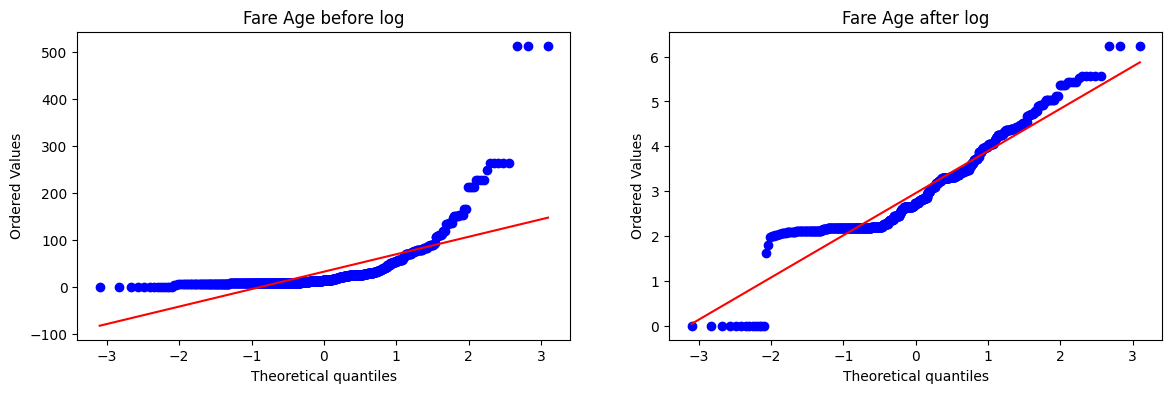

In [27]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(x_train['Fare'], dist="norm", plot=plt)
plt.title("Fare Age before log")

plt.subplot(122)
stats.probplot(x_train_transformed['Fare'], dist="norm", plot=plt)
plt.title("Fare Age after log")

plt.show()

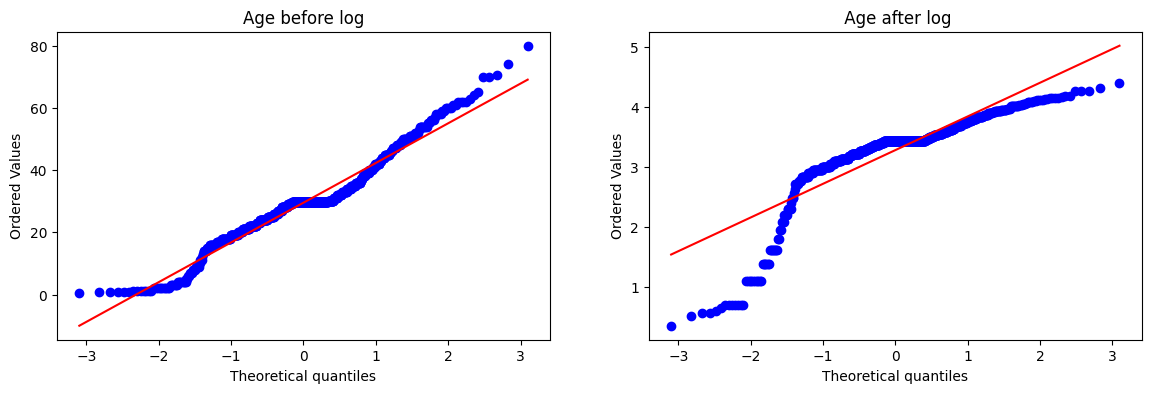

In [28]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(x_train['Age'], dist="norm", plot=plt)
plt.title("Age before log")

plt.subplot(122)
stats.probplot(x_train_transformed['Age'], dist="norm", plot=plt)
plt.title(" Age after log")

plt.show()

# same work as upper jisa 

In [29]:
trf2 = ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')
x_train_transformed2 = trf2.fit_transform(x_train)
x_test_transformed2 = trf2.transform(x_test)

In [30]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train_transformed2,y_train)
clf2.fit(x_train_transformed2,y_train)

y_pred = clf.predict(x_test_transformed2)
y_pred2 = clf2.predict(x_test_transformed2)

print("accuracy LR", accuracy_score(y_test,y_pred))
print("accuracy DT", accuracy_score(y_test,y_pred2))

accuracy LR 0.6703910614525139
accuracy DT 0.6759776536312849


In [31]:


x_transformed2 = trf2.fit_transform(x)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("lr", np.mean(cross_val_score(clf, x_transformed2,y,scoring='accuracy',cv=10)))
print("dt", np.mean(cross_val_score(clf2, x_transformed2,y,scoring='accuracy',cv=10)))

lr 0.6712609238451936
dt 0.6621972534332083


In [32]:
def apply_transformed(transform):
    x = df.iloc[:,1:3]
    y = df.iloc[:,0]

    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')

    x_trans = trf.fit_transform(x)

    clf = LogisticRegression()
    
    print("accuracy", np.mean(cross_val_score(clf, x_trans, y, scoring='accuracy',cv=10)))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(x['Fare'], dist="norm", plot=plt)
    plt.title("Fare before transform")

    plt.subplot(122)
    stats.probplot(x_trans[:,0], dist="norm", plot=plt)
    plt.title(" Fare after transform")

    plt.show()

    



accuracy 0.6589013732833957


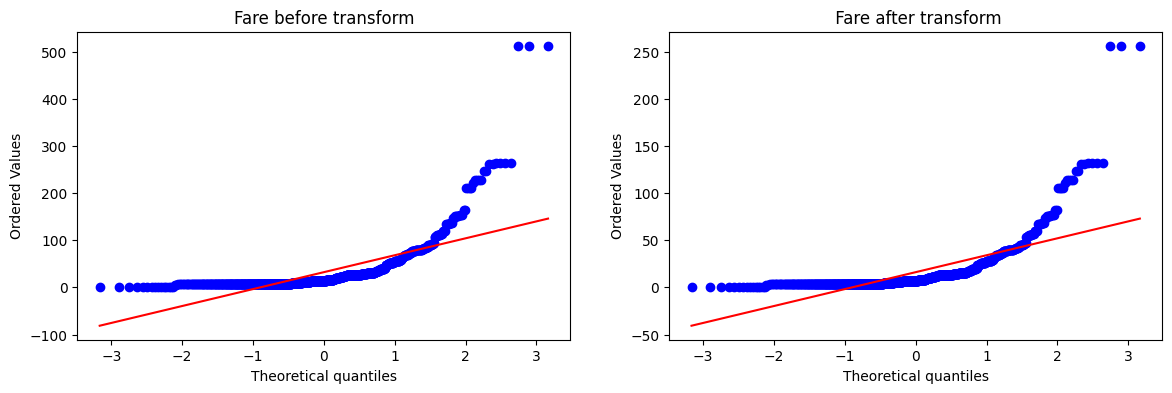

In [35]:
apply_transformed(lambda x : x**1/2)

accuracy 0.6431335830212235


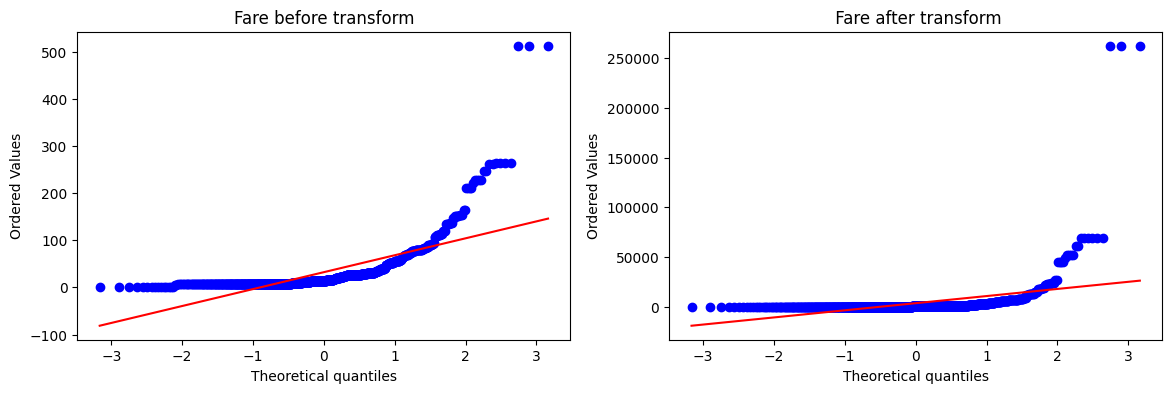

In [34]:
apply_transformed(lambda x : x**2)

accuracy 0.616167290886392


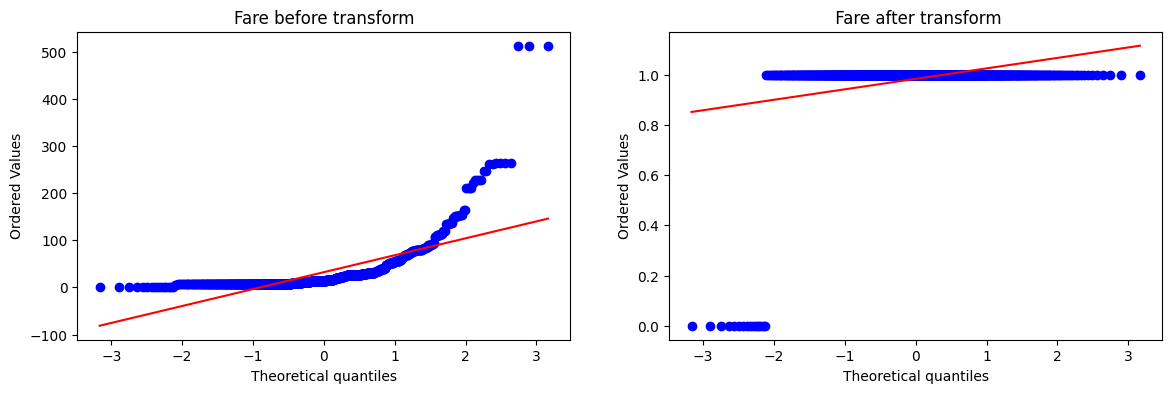

In [38]:
apply_transformed(lambda x : x/(x+0.000001))

accuracy 0.6195131086142323


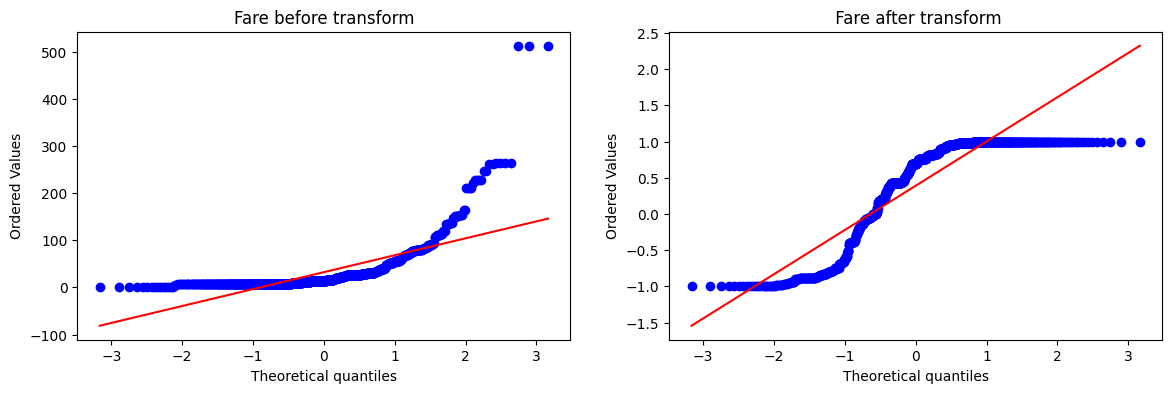

In [39]:
apply_transformed(np.sin)